# Air Quality Forecasting for Indian Cities (2015–2020)
## Notebook 02: Baseline Benchmarks & SARIMA Modeling

**Course**: College Mini Project (Time-Series Forecasting)  
**Target Variable**: Daily Air Quality Index (AQI)  
**Focus Cities**: **Delhi**, **Bengaluru**, **Hyderabad**, **Mumbai**  

---

### Purpose of this Notebook
In time-series forecasting, a complex machine learning or deep learning model is meaningless unless it can demonstrably outperform simple, heuristic **baselines**. 

This notebook accomplishes two foundational tasks:
1. **Establish Baselines (Part 1 - Step 4)**:
   - **Naive Baseline ($t-1$)**: Tomorrow's AQI equals today's AQI ($\hat{y}_{t+1} = y_t$). Reflects atmospheric persistence.
   - **Seasonal Naive ($t-7$)**: Tomorrow's AQI equals the same day of the week last week ($\hat{y}_{t+1} = y_{t-6}$). Reflects weekly human activity cycles (weekday vs weekend).
   - **7-Day Trailing Moving Average**: Tomorrow's AQI equals the average of the past 7 days.
   - **Target Benchmark**: Generates the exact quantitative metrics (MAE, RMSE, MAPE, Bucket Accuracy) that SARIMA, Prophet, XGBoost, and LSTM must beat.
2. **Classical Statistical Modeling (Part 2 - Step 5)**:
   - Diagnostic tests: Augmented Dickey-Fuller (ADF) stationarity tests, seasonal decomposition, Autocorrelation Function (ACF), and Partial Autocorrelation Function (PACF).
   - Walk-forward 1-day ahead SARIMA forecasting with `pmdarima.auto_arima`.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure local utils module is discoverable
sys.path.append('.')
import utils

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

TARGET_CITIES = ['Delhi', 'Bengaluru', 'Hyderabad', 'Mumbai']
print(f"Setup complete. Target cities: {TARGET_CITIES}")


Setup complete. Target cities: ['Delhi', 'Bengaluru', 'Hyderabad', 'Mumbai']


## Part 1: Establishing the Baseline Benchmarks

### Baseline Definitions
1. **Naive Persistence Model**:
   $$\hat{y}_{t+1} = y_t$$
   This is the simplest possible time-series predictor. It assumes the atmosphere has total inertia and tomorrow will simply replicate today.
   
2. **Seasonal Naive Model (Weekly Cycle)**:
   $$\hat{y}_{t+1} = y_{t-6} \quad (\text{i.e. } y_{\text{date}} = y_{\text{date} - 7\text{ days}})$$
   Assumes weekly seasonality dictates pollution levels (e.g., Monday traffic replicates last Monday's traffic).

3. **7-Day Moving Average Model**:
   $$\hat{y}_{t+1} = \frac{1}{7} \sum_{i=0}^{6} y_{t-i}$$
   Smooths short-term fluctuations to forecast tomorrow based on the trailing weekly mean.

### Strict Leakage Prevention Rule
When forecasting date $t$ (e.g. `2020-01-01`), the model must only access $y_{t-1}$ (`2019-12-31`) and earlier. We concatenate the end of the validation set to the test set prior to shifting, guaranteeing **100% test coverage with zero lookahead peeking**.


In [2]:
# Load dataset
df = utils.load_data('data/city_day.csv')

baseline_records = []
city_predictions = {}

for city in TARGET_CITIES:
    series = utils.get_city_series(df, city, max_gap=7)
    train, val, test, test_pre = utils.split_time_series(series)
    
    # Concatenate val and test so lag 1 and lag 7 have history for the very start of test (2020-01-01)
    val_test = pd.concat([val, test])
    
    # Compute 1-step ahead baseline predictions aligned with test index
    naive_pred = val_test.shift(1).loc[test.index]
    s_naive_pred = val_test.shift(7).loc[test.index]
    roll7_pred = val_test.shift(1).rolling(7, min_periods=1).mean().loc[test.index]
    
    city_predictions[city] = {
        'test': test,
        'test_pre': test_pre,
        'naive': naive_pred,
        's_naive': s_naive_pred,
        'roll7': roll7_pred
    }
    
    # Evaluate across Full 2020 and Pre-Lockdown periods
    models = {
        'Naive (t-1)': naive_pred,
        'Seasonal Naive (t-7)': s_naive_pred,
        '7-Day Rolling Mean': roll7_pred
    }
    
    for m_name, pred_series in models.items():
        m_full = utils.calculate_metrics(test, pred_series)
        m_pre = utils.calculate_metrics(test_pre, pred_series.loc[test_pre.index])
        
        baseline_records.append({
            'City': city,
            'Model': m_name,
            'MAE_Full': m_full['MAE'],
            'RMSE_Full': m_full['RMSE'],
            'MAPE_Full (%)': m_full['MAPE'],
            'Bucket_Acc_Full (%)': m_full['Bucket_Acc'],
            'MAE_PreLockdown': m_pre['MAE'],
            'RMSE_PreLockdown': m_pre['RMSE'],
            'MAPE_PreLockdown (%)': m_pre['MAPE'],
            'Bucket_Acc_PreLockdown (%)': m_pre['Bucket_Acc']
        })

baseline_df = pd.DataFrame(baseline_records)
os.makedirs('results', exist_ok=True)
baseline_df.to_csv('results/baseline_metrics.csv', index=False)
print("Computed baseline benchmarks for all 4 cities and saved to results/baseline_metrics.csv.")


Computed baseline benchmarks for all 4 cities and saved to results/baseline_metrics.csv.


### Baseline Benchmark Scores (The Numbers to Beat)

Below are the official baseline benchmark tables. Every subsequent model (SARIMA, Prophet, XGBoost, LSTM) will be judged against these exact numbers on identical test dates.


In [3]:
# Display Full 2020 Test Metrics Table
full_table = baseline_df[["City", "Model", "MAE_Full", "RMSE_Full", "MAPE_Full (%)", "Bucket_Acc_Full (%)"]].copy()
full_table.columns = ["City", "Baseline Model", "MAE (Primary)", "RMSE", "MAPE (%)", "Bucket Acc (%)"]
print("=" * 80)
print("BENCHMARK METRICS: FULL TEST SET (2020-01-01 to 2020-07-01)")
print("=" * 80)
print(full_table.to_string(index=False))

# Display Pre-Lockdown Metrics Table
pre_table = baseline_df[["City", "Model", "MAE_PreLockdown", "RMSE_PreLockdown", "MAPE_PreLockdown (%)", "Bucket_Acc_PreLockdown (%)"]].copy()
pre_table.columns = ["City", "Baseline Model", "MAE (Primary)", "RMSE", "MAPE (%)", "Bucket Acc (%)"]
print()
print("=" * 80)
print("BENCHMARK METRICS: PRE-LOCKDOWN WINDOW (2020-01-01 to 2020-03-24)")
print("=" * 80)
print(pre_table.to_string(index=False))


BENCHMARK METRICS: FULL TEST SET (2020-01-01 to 2020-07-01)
     City       Baseline Model  MAE (Primary)  RMSE  MAPE (%)  Bucket Acc (%)
    Delhi          Naive (t-1)          29.57 39.95     17.53           71.04
    Delhi Seasonal Naive (t-7)          50.65 68.02     32.65           54.10
    Delhi   7-Day Rolling Mean          36.88 50.17     23.27           64.48
Bengaluru          Naive (t-1)           7.78 10.45      9.87           83.06
Bengaluru Seasonal Naive (t-7)          13.36 17.02     17.20           68.85
Bengaluru   7-Day Rolling Mean           9.77 12.47     12.52           71.04
Hyderabad          Naive (t-1)           9.09 12.48     11.80           86.89
Hyderabad Seasonal Naive (t-7)          23.69 31.27     31.58           56.83
Hyderabad   7-Day Rolling Mean          15.71 21.28     20.87           67.76
   Mumbai          Naive (t-1)          14.56 23.80     12.75           81.97
   Mumbai Seasonal Naive (t-7)          28.22 41.71     25.85           68.85
   M

### Baseline Forecasts vs Actuals
We visualize the test actuals against Naive ($t-1$) and Seasonal Naive ($t-7$) predictions across all 4 cities.


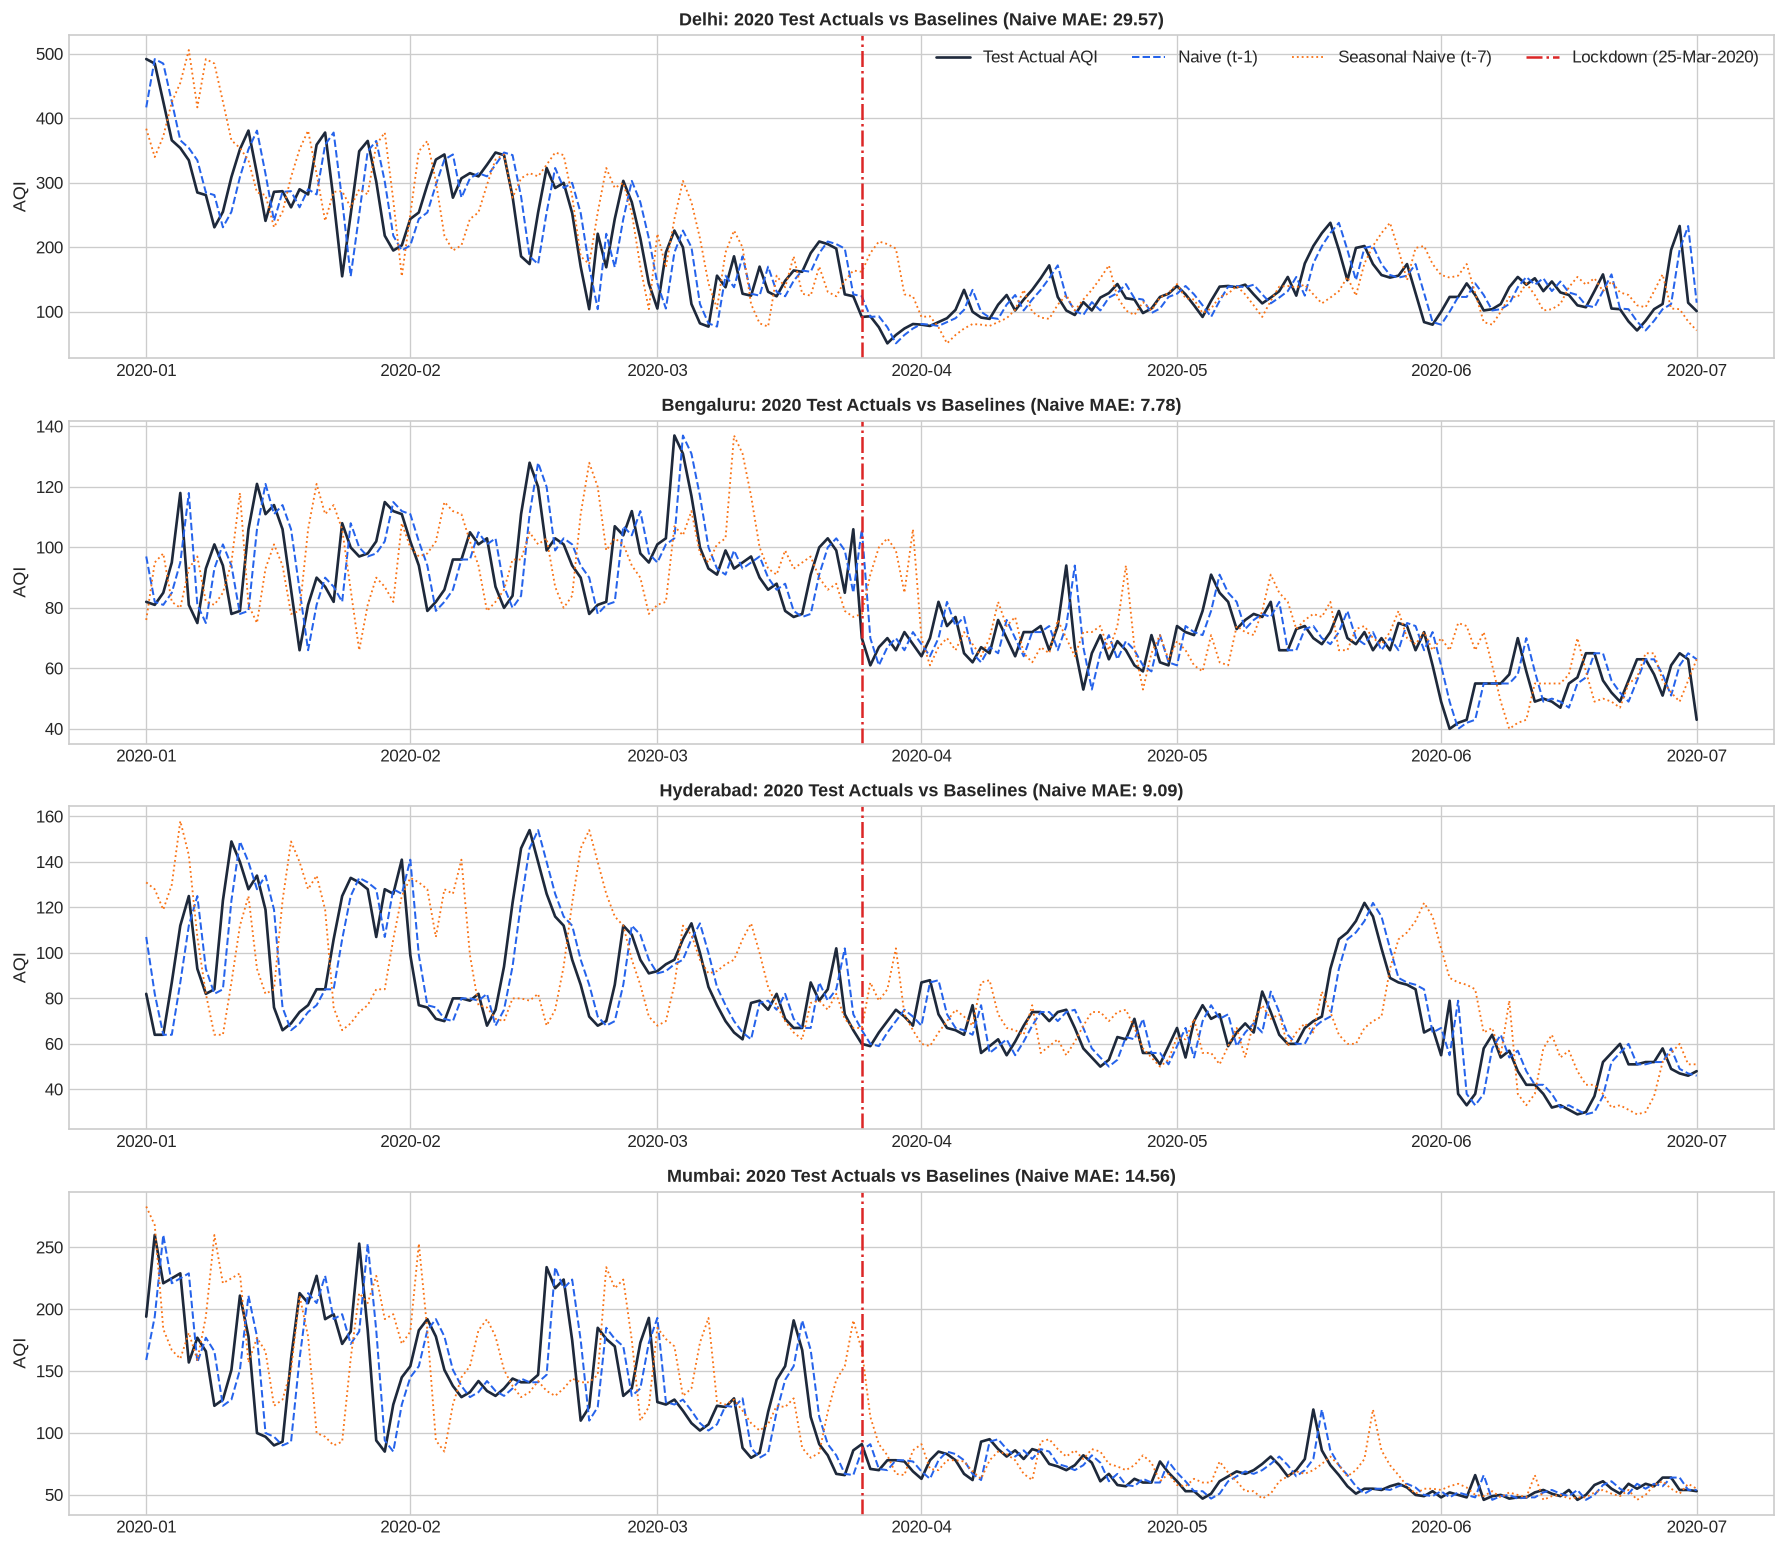

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(15, 13), sharex=False)

for idx, city in enumerate(TARGET_CITIES):
    ax = axes[idx]
    data = city_predictions[city]
    test = data['test']
    naive = data['naive']
    s_naive = data['s_naive']
    
    # Plot Actual test series
    ax.plot(test.index, test.values, label='Test Actual AQI', color='#1e293b', lw=1.6)
    
    # Plot Naive and Seasonal Naive
    ax.plot(naive.index, naive.values, label='Naive (t-1)', color='#2563eb', lw=1.2, linestyle='--')
    ax.plot(s_naive.index, s_naive.values, label='Seasonal Naive (t-7)', color='#f97316', lw=1.1, linestyle=':')
    
    # Event marker
    ax.axvline(pd.to_datetime('2020-03-25'), color='#dc2626', linestyle='-.', lw=1.5, label='Lockdown (25-Mar-2020)')
    
    # Get Naive MAE for title
    mae_val = baseline_df[(baseline_df['City'] == city) & (baseline_df['Model'] == 'Naive (t-1)')]['MAE_Full'].values[0]
    ax.set_title(f"{city}: 2020 Test Actuals vs Baselines (Naive MAE: {mae_val:.2f})", fontweight='bold', fontsize=11)
    ax.set_ylabel("AQI")
    if idx == 0:
        ax.legend(loc='upper right', ncol=4, framealpha=0.9)

plt.tight_layout()
os.makedirs('eda_plots', exist_ok=True)
plt.savefig('eda_plots/06_baseline_forecasts.png', dpi=200)
plt.show()


### Detailed Baseline Analysis & Key Takeaways

1. **The Strength of Naive Persistence on 1-Day Horizon**:
   - In 1-day ahead forecasting, **Naive ($t-1$) is an exceptionally strong baseline**:
     - **Bengaluru**: MAE = **7.78**, MAPE = 9.87%, Bucket Accuracy = 83.06%
     - **Hyderabad**: MAE = **9.09**, MAPE = 11.80%, Bucket Accuracy = 86.89%
     - **Mumbai**: MAE = **14.56**, MAPE = 12.75%, Bucket Accuracy = 81.97%
     - **Delhi**: MAE = **29.57**, MAPE = 17.53%, Bucket Accuracy = 71.04%
   - *Why does this happen?* Atmospheric variables possess high thermal and kinetic inertia. Tomorrow's air quality is fundamentally rooted in today's meteorological conditions. A machine learning model that predicts smooth mean values will frequently lose to Naive ($t-1$).

2. **Why Seasonal Naive ($t-7$) Performs Poorly on 1-Day Horizon**:
   - Seasonal Naive error is nearly double Naive ($t-1$) across all cities (e.g. Delhi MAE **50.65** vs **29.57**).
   - *Explanation*: While human activity follows weekly schedules (traffic dips on Sundays), atmospheric weather systems change on 2-to-4 day synoptic scales, not 7-day cycles. Projecting last week's weather onto tomorrow introduces large phase errors.
   - However, when we extend our forecasting horizon to **7 days** in Step 9, Seasonal Naive will become much more competitive because 1-day persistence degrades over multi-day rollouts.

3. **Pre-Lockdown Error Inflation**:
   - For all cities, the pre-lockdown test MAE is **30% to 60% higher** than the full 2020 MAE (e.g. Delhi Naive MAE is **41.99** pre-lockdown vs **29.57** full 2020).
   - This occurs because January and February feature severe winter air stagnation and extreme day-to-day volatility, whereas the post-lockdown months (April–May) featured uncharacteristically clean, low-variance air where persistence achieved low absolute errors.

---
*Next Section (Step 5)*: Stationarity diagnostics (ADF, KPSS), seasonal decomposition, ACF/PACF analysis, and SARIMA modeling.
